### Name: Runal Gavade
### Roll No: 62
### Assignment-9

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score,
    roc_auc_score, roc_curve,
    classification_report
)

In [2]:
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

print(df.shape)
print(df.columns)
print(df.head())
print("Shape:", df.shape)
print(df.isnull().sum())

(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
Shape: (768, 9)
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness              

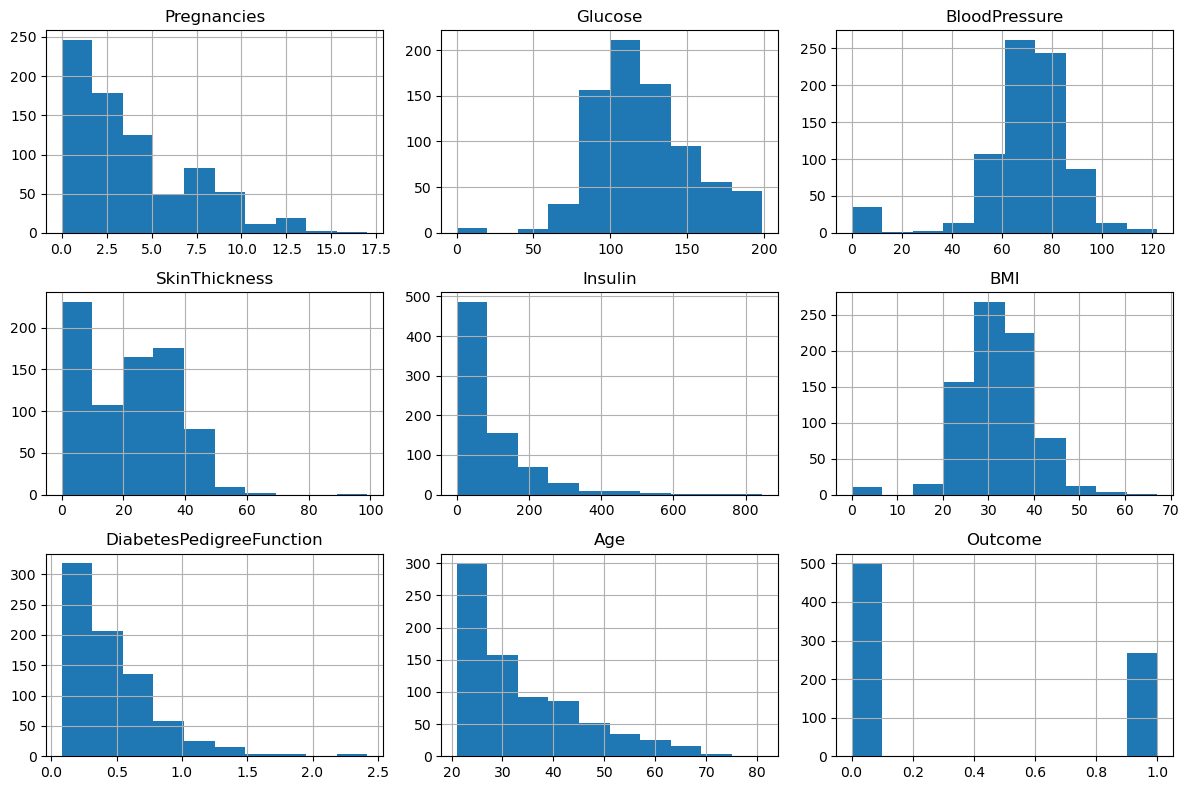

In [3]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

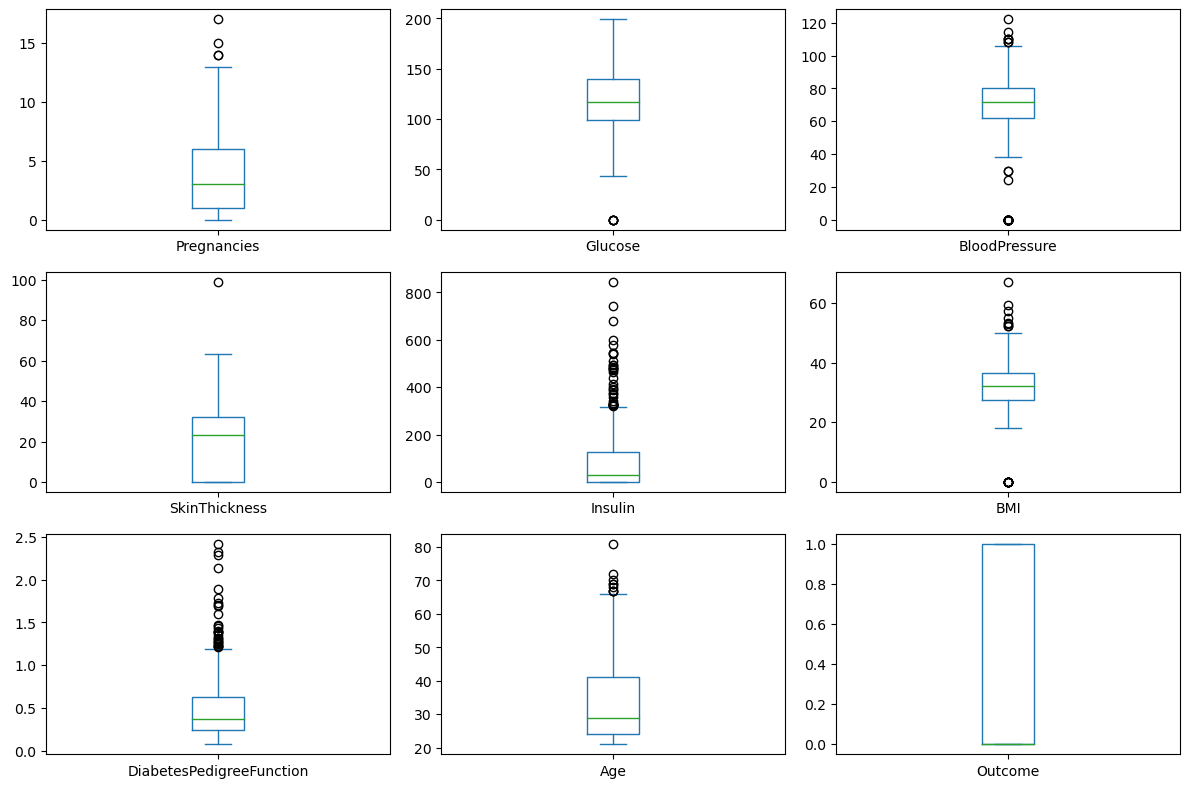

In [4]:
df.plot(
    kind="box",
    subplots=True,
    layout=(3, 3),
    figsize=(12, 8),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

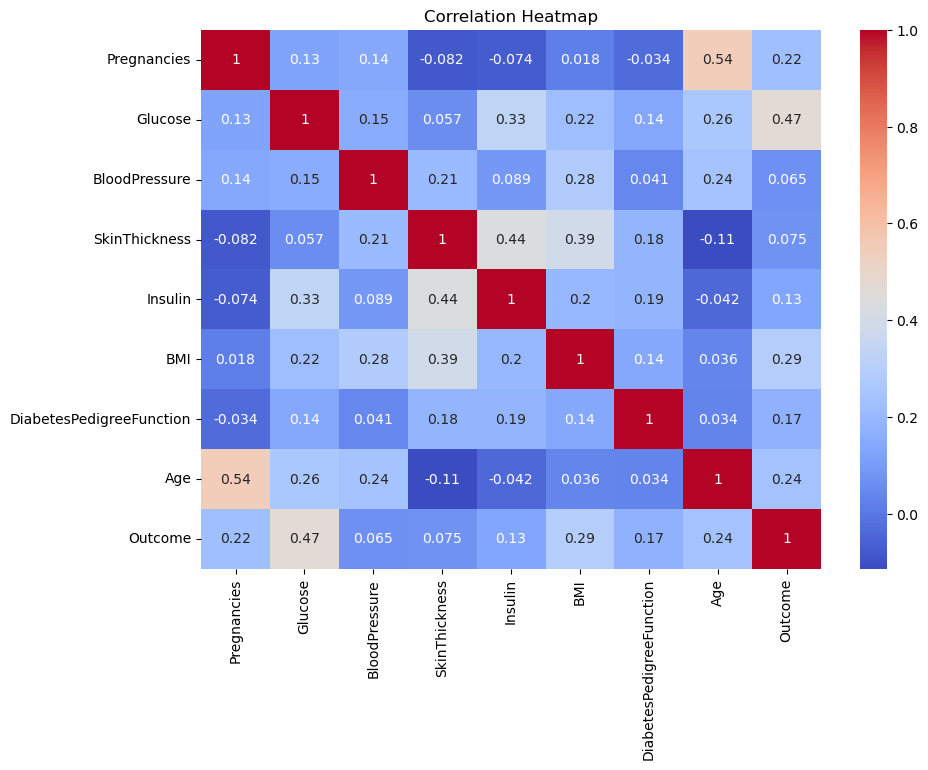

In [5]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [6]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

for col in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]:
    if col in X.columns:
        X[col] = X[col].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 614
Testing rows: 154


In [7]:
knn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=3))
])

knn.fit(X_train, y_train)

pred = knn.predict(X_test)
prob = knn.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, pred)
acc = accuracy_score(y_test, pred)

print("\nKNN CONFUSION MATRIX")
print(cm)
print("Accuracy:", round(acc, 4))
print("Error Rate:", round(1 - acc, 4))
print("Precision:", round(precision_score(y_test, pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 4))
print(classification_report(y_test, pred, zero_division=0))


KNN CONFUSION MATRIX
[[86 14]
 [24 30]]
Accuracy: 0.7532
Error Rate: 0.2468
Precision: 0.6818
Recall: 0.5556
ROC-AUC: 0.7774
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       100
           1       0.68      0.56      0.61        54

    accuracy                           0.75       154
   macro avg       0.73      0.71      0.72       154
weighted avg       0.75      0.75      0.75       154



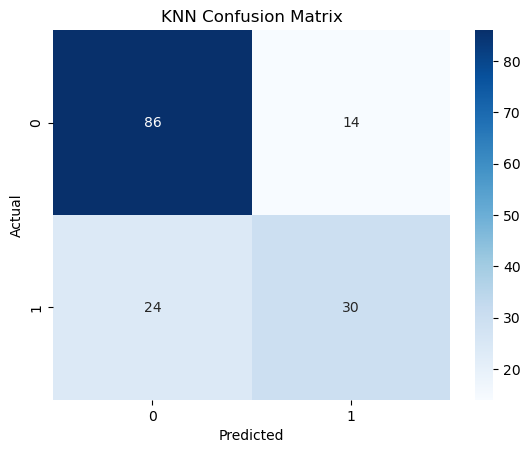

In [8]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")
plt.show()

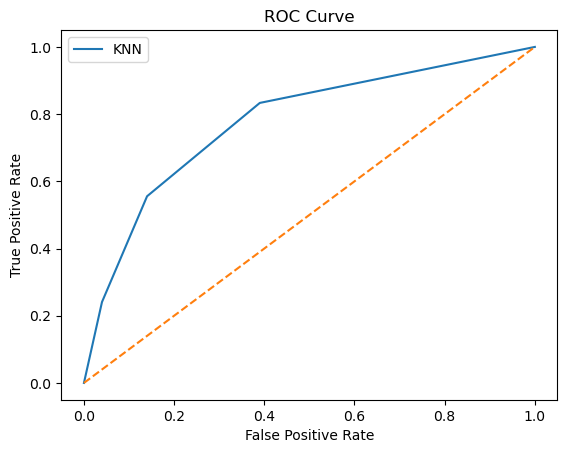

In [9]:
fpr, tpr, _ = roc_curve(y_test, prob)

plt.plot(fpr, tpr, label="KNN")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [10]:
grid = GridSearchCV(
    knn,
    {"model__n_neighbors": range(1, 25)},
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best K:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))
print("Tuned KNN test accuracy:",
      round(accuracy_score(y_test, grid.predict(X_test)), 4))

Best K: {'model__n_neighbors': 19}
Best CV accuracy: 0.7719
Tuned KNN test accuracy: 0.7727


In [11]:
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=1
    ))
])

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

rf_acc = accuracy_score(y_test, rf_pred)
rf_cm = confusion_matrix(y_test, rf_pred)

print("\nRANDOM FOREST CONFUSION MATRIX")
print(rf_cm)
print("Accuracy:", round(rf_acc, 4))
print("Error Rate:", round(1 - rf_acc, 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))
print(classification_report(y_test, rf_pred, zero_division=0))


RANDOM FOREST CONFUSION MATRIX
[[87 13]
 [26 28]]
Accuracy: 0.7468
Error Rate: 0.2532
Precision: 0.6829
Recall: 0.5185
ROC-AUC: 0.8169
              precision    recall  f1-score   support

           0       0.77      0.87      0.82       100
           1       0.68      0.52      0.59        54

    accuracy                           0.75       154
   macro avg       0.73      0.69      0.70       154
weighted avg       0.74      0.75      0.74       154



In [12]:
results = pd.DataFrame({
    "Model": ["KNN", "Random Forest"],
    "Accuracy": [acc, rf_acc],
    "Error Rate": [1 - acc, 1 - rf_acc]
})

print("\nMODEL COMPARISON")
print(results.round(4))


MODEL COMPARISON
           Model  Accuracy  Error Rate
0            KNN    0.7532      0.2468
1  Random Forest    0.7468      0.2532
